# **Week 14 – Hotel Booking Visualization, Revenue Management & Hospitality Insights**

1. Import libraries and upload the dataset

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil

df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/hotel_bookings_cleaned.csv")

df.columns = df.columns.str.strip()

print("Dataset loaded successfully")

print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully
Dataset shape: (87395, 44)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,arrival_date,total_nights,is_family,has_booking_changes,has_special_requests,arrival_year,arrival_month,arrival_month_name,arrival_quarter,booking_status
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,2015-07-01,0,False,True,False,2015,7,July,Q3,Not Canceled
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,2015-07-01,0,False,True,False,2015,7,July,Q3,Not Canceled
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,2015-07-01,1,False,False,False,2015,7,July,Q3,Not Canceled
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,2015-07-01,1,False,False,False,2015,7,July,Q3,Not Canceled
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,2015-07-01,2,False,False,True,2015,7,July,Q3,Not Canceled


2. Explore the dataset

In [35]:
print("Dataset Information")
df.info()

print("\nDataset Shape")
print(df.shape)

print("\nColumn Names")
print(df.columns.tolist())

print("\nMissing Values")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Records")
print(df.duplicated().sum())

print("\nHotel Types")
display(df["hotel"].value_counts())

print("\nCancellation Status")
display(df["is_canceled"].value_counts())

print("\nMarket Segments")
display(df["market_segment"].value_counts())

print("\nReservation Status")
display(df["reservation_status"].value_counts())

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87395 entries, 0 to 87394
Data columns (total 44 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87395 non-null  object 
 1   is_canceled                     87395 non-null  int64  
 2   lead_time                       87395 non-null  int64  
 3   arrival_date_year               87395 non-null  int64  
 4   arrival_date_month              87395 non-null  object 
 5   arrival_date_week_number        87395 non-null  int64  
 6   arrival_date_day_of_month       87395 non-null  int64  
 7   stays_in_weekend_nights         87395 non-null  int64  
 8   stays_in_week_nights            87395 non-null  int64  
 9   adults                          87395 non-null  int64  
 10  children                        87395 non-null  float64
 11  babies                          87395 non-null  int64  
 12  meal        

,Missing Values
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0



Duplicate Records
0

Hotel Types


,count
hotel,
City Hotel,53428
Resort Hotel,33967



Cancellation Status


,count
is_canceled,
0,63370
1,24025



Market Segments


,count
market_segment,
Online TA,51618
Offline TA/TO,13889
Direct,11804
Groups,4941
Corporate,4212
Complementary,702
Aviation,227
Undefined,2



Reservation Status


,count
reservation_status,
Check-Out,63370
Canceled,23011
No-Show,1014


3. Prepare the dataset

In [36]:
required_columns = [
    "hotel",
    "is_canceled",
    "lead_time",
    "market_segment",
    "arrival_date",
    "arrival_year",
    "arrival_month",
    "adr",
    "reservation_status",
    "total_nights"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

numeric_columns = [
    "is_canceled",
    "lead_time",
    "arrival_year",
    "arrival_month",
    "adr",
    "total_nights"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

df["arrival_date"] = pd.to_datetime(
    df["arrival_date"],
    errors="coerce"
)

df = df.dropna(
    subset=[
        "hotel",
        "is_canceled",
        "lead_time",
        "market_segment",
        "arrival_date",
        "arrival_year",
        "arrival_month",
        "adr",
        "reservation_status",
        "total_nights"
    ]
).copy()

df = df[df["is_canceled"].isin([0, 1])].copy()

df = df[df["lead_time"] >= 0].copy()

df["cancellation_status"] = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

df["arrival_month_name"] = df["arrival_date"].dt.month_name()

df["arrival_year_month"] = (
    df["arrival_date"].dt.to_period("M").astype(str)
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

print("Prepared Dataset Shape:", df.shape)

display(df.head())

Prepared Dataset Shape: (87395, 46)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,is_family,has_booking_changes,has_special_requests,arrival_year,arrival_month,arrival_month_name,arrival_quarter,booking_status,cancellation_status,arrival_year_month
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,False,True,False,2015,7,July,Q3,Not Canceled,Not Canceled,2015-07
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,False,True,False,2015,7,July,Q3,Not Canceled,Not Canceled,2015-07
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,False,False,False,2015,7,July,Q3,Not Canceled,Not Canceled,2015-07
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,False,False,False,2015,7,July,Q3,Not Canceled,Not Canceled,2015-07
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,False,False,True,2015,7,July,Q3,Not Canceled,Not Canceled,2015-07


4. Compare booking demand between City Hotel and Resort Hotel

,hotel,total_bookings,canceled_bookings,average_lead_time,average_adr,not_canceled_bookings,cancellation_rate
0,City Hotel,53428,16049,77.678521,110.985944,37379,30.038557
1,Resort Hotel,33967,7976,83.368652,99.028449,25991,23.481615


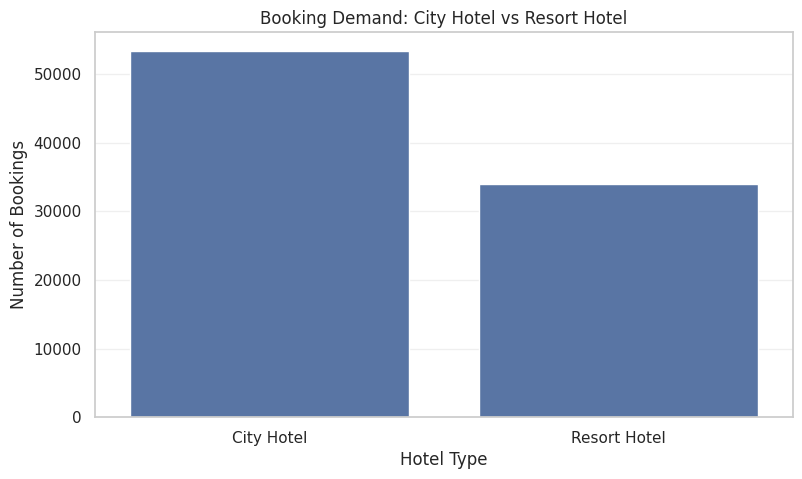

In [37]:
hotel_demand = (
    df.groupby("hotel")
    .agg(
        total_bookings=("hotel", "count"),
        canceled_bookings=("is_canceled", "sum"),
        average_lead_time=("lead_time", "mean"),
        average_adr=("adr", "mean")
    )
    .reset_index()
)

hotel_demand["not_canceled_bookings"] = (
    hotel_demand["total_bookings"] -
    hotel_demand["canceled_bookings"]
)

hotel_demand["cancellation_rate"] = (
    hotel_demand["canceled_bookings"] /
    hotel_demand["total_bookings"]
) * 100

display(hotel_demand)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hotel_demand,
    x="hotel",
    y="total_bookings"
)

plt.title("Booking Demand: City Hotel vs Resort Hotel")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.grid(axis="y", alpha=0.3)
plt.show()

5. Compare cancellation rates across hotel types

,hotel,total_bookings,canceled_bookings,cancellation_rate
0,City Hotel,53428,16049,30.038557
1,Resort Hotel,33967,7976,23.481615


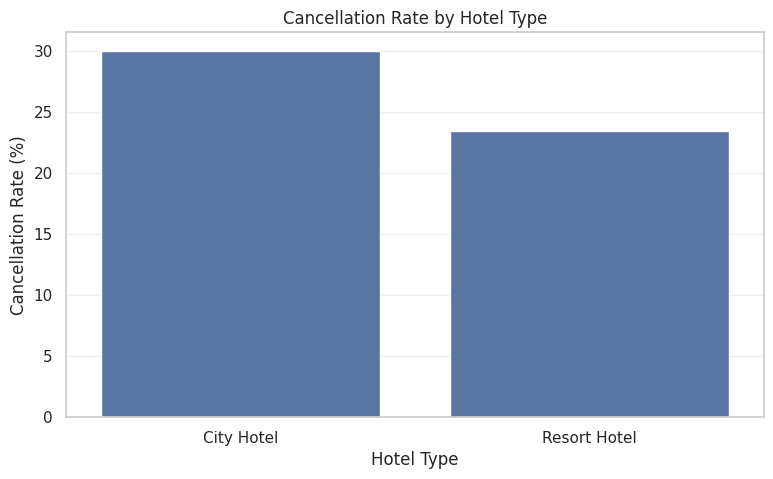

In [38]:
hotel_cancellation = (
    df.groupby("hotel")
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

hotel_cancellation["cancellation_rate"] = (
    hotel_cancellation["canceled_bookings"] /
    hotel_cancellation["total_bookings"]
) * 100

display(hotel_cancellation)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hotel_cancellation,
    x="hotel",
    y="cancellation_rate"
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

6. Compare cancellation rates across market segments

,market_segment,total_bookings,canceled_bookings,not_canceled_bookings,cancellation_rate
7,Undefined,2,2,0,100.000000
6,Online TA,51618,18245,33373,35.346197
4,Groups,4941,1335,3606,27.018822
0,Aviation,227,45,182,19.823789
5,Offline TA/TO,13889,2063,11826,14.853481
3,Direct,11804,1737,10067,14.715351
1,Complementary,702,88,614,12.535613
2,Corporate,4212,510,3702,12.108262


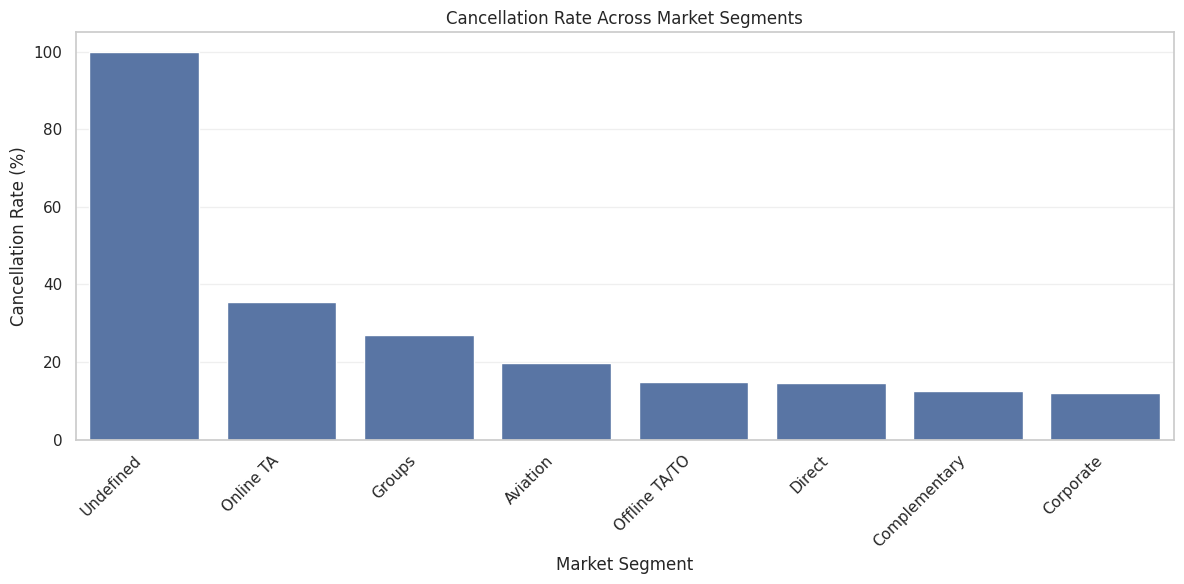

In [39]:
market_analysis = (
    df.groupby("market_segment")
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

market_analysis["not_canceled_bookings"] = (
    market_analysis["total_bookings"] -
    market_analysis["canceled_bookings"]
)

market_analysis["cancellation_rate"] = (
    market_analysis["canceled_bookings"] /
    market_analysis["total_bookings"]
) * 100

market_analysis = market_analysis.sort_values(
    "cancellation_rate",
    ascending=False
)

display(market_analysis)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=market_analysis,
    x="market_segment",
    y="cancellation_rate"
)

plt.title("Cancellation Rate Across Market Segments")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

7. Compare cancellation rates by market segment and hotel type

,market_segment,hotel,total_bookings,canceled_bookings,cancellation_rate
0,Aviation,City Hotel,227,45,19.823789
1,Complementary,City Hotel,513,57,11.111111
2,Complementary,Resort Hotel,189,31,16.402116
3,Corporate,City Hotel,2227,264,11.854513
4,Corporate,Resort Hotel,1985,246,12.392947
5,Direct,City Hotel,5559,912,16.405828
6,Direct,Resort Hotel,6245,825,13.210568
7,Groups,City Hotel,2635,890,33.776091
8,Groups,Resort Hotel,2306,445,19.297485
9,Offline TA/TO,City Hotel,7271,1261,17.342869


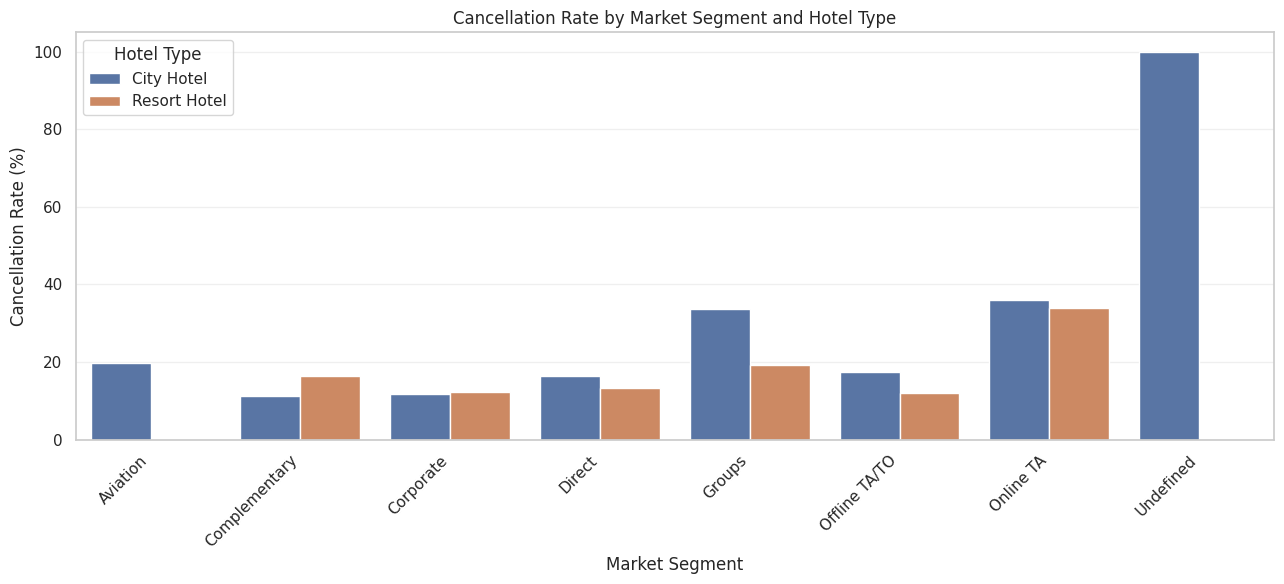

In [40]:
segment_hotel_analysis = (
    df.groupby(["market_segment", "hotel"])
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

segment_hotel_analysis["cancellation_rate"] = (
    segment_hotel_analysis["canceled_bookings"] /
    segment_hotel_analysis["total_bookings"]
) * 100

display(segment_hotel_analysis)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=segment_hotel_analysis,
    x="market_segment",
    y="cancellation_rate",
    hue="hotel"
)

plt.title("Cancellation Rate by Market Segment and Hotel Type")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Hotel Type")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

8. Analyze monthly arrival trends

,arrival_year,arrival_month,arrival_month_name,total_arrivals
0,2015,7,July,1674
1,2015,8,August,2453
2,2015,9,September,2839
3,2015,10,October,2700
4,2015,11,November,1665
5,2015,12,December,1982
6,2016,1,January,1849
7,2016,2,February,2806
8,2016,3,March,3831
9,2016,4,April,3770


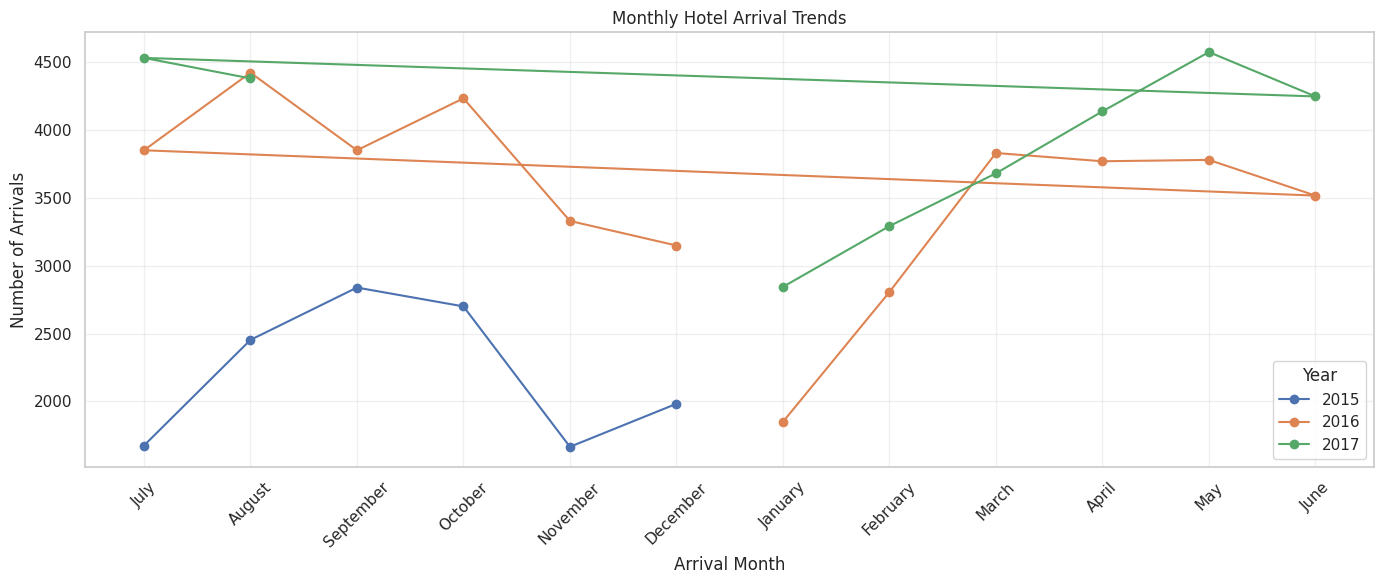

In [41]:
monthly_arrivals = (
    df.groupby(
        ["arrival_year", "arrival_month", "arrival_month_name"]
    )
    .size()
    .reset_index(name="total_arrivals")
)

monthly_arrivals["arrival_month_name"] = pd.Categorical(
    monthly_arrivals["arrival_month_name"],
    categories=month_order,
    ordered=True
)

monthly_arrivals = monthly_arrivals.sort_values(
    ["arrival_year", "arrival_month"]
)

display(monthly_arrivals)

plt.figure(figsize=(14, 6))

for year in sorted(monthly_arrivals["arrival_year"].unique()):

    year_data = monthly_arrivals[
        monthly_arrivals["arrival_year"] == year
    ]

    plt.plot(
        year_data["arrival_month_name"].astype(str),
        year_data["total_arrivals"],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Hotel Arrival Trends")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Arrivals")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

9. Analyze monthly ADR fluctuations

,arrival_year,arrival_month,arrival_month_name,average_adr,median_adr,completed_bookings
0,2015,7,July,118.431287,117.715,1142
1,2015,8,August,122.616044,115.670,1863
2,2015,9,September,100.777940,96.000,2262
3,2015,10,October,79.806912,75.000,2225
4,2015,11,November,59.235591,60.000,1397
5,2015,12,December,71.240032,65.000,1572
6,2016,1,January,62.012125,62.250,1525
7,2016,2,February,69.627645,68.500,2255
8,2016,3,March,75.555922,72.000,2911
9,2016,4,April,88.206411,86.670,2733


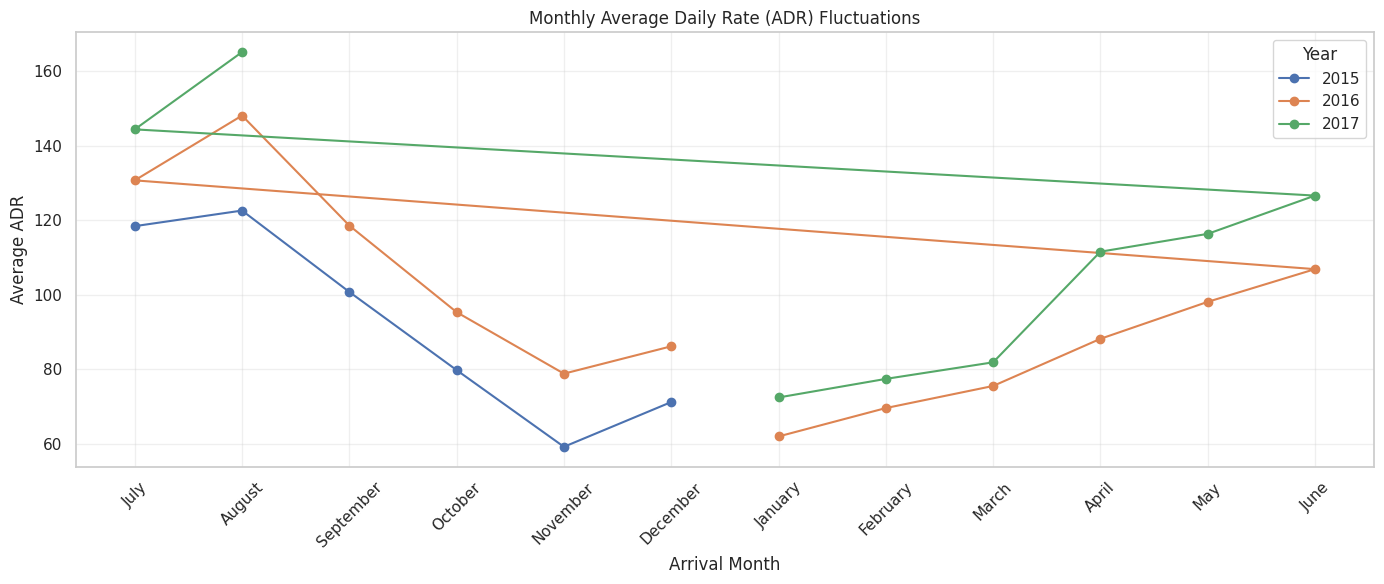

In [42]:
completed_stays = df[
    df["reservation_status"] == "Check-Out"
].copy()

completed_stays = completed_stays[
    (completed_stays["adr"] >= 0) &
    (completed_stays["total_nights"] > 0)
].copy()

monthly_adr = (
    completed_stays
    .groupby(
        ["arrival_year", "arrival_month", "arrival_month_name"]
    )
    .agg(
        average_adr=("adr", "mean"),
        median_adr=("adr", "median"),
        completed_bookings=("adr", "count")
    )
    .reset_index()
)

monthly_adr["arrival_month_name"] = pd.Categorical(
    monthly_adr["arrival_month_name"],
    categories=month_order,
    ordered=True
)

monthly_adr = monthly_adr.sort_values(
    ["arrival_year", "arrival_month"]
)

display(monthly_adr)

plt.figure(figsize=(14, 6))

for year in sorted(monthly_adr["arrival_year"].unique()):

    year_data = monthly_adr[
        monthly_adr["arrival_year"] == year
    ]

    plt.plot(
        year_data["arrival_month_name"].astype(str),
        year_data["average_adr"],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Average Daily Rate (ADR) Fluctuations")
plt.xlabel("Arrival Month")
plt.ylabel("Average ADR")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

10. Generate box plots for lead time distributions

,cancellation_status,total_bookings,average_lead_time,median_lead_time,minimum_lead_time,maximum_lead_time
0,Canceled,24025,105.719251,80.0,0,629
1,Not Canceled,63370,70.097617,38.0,0,737


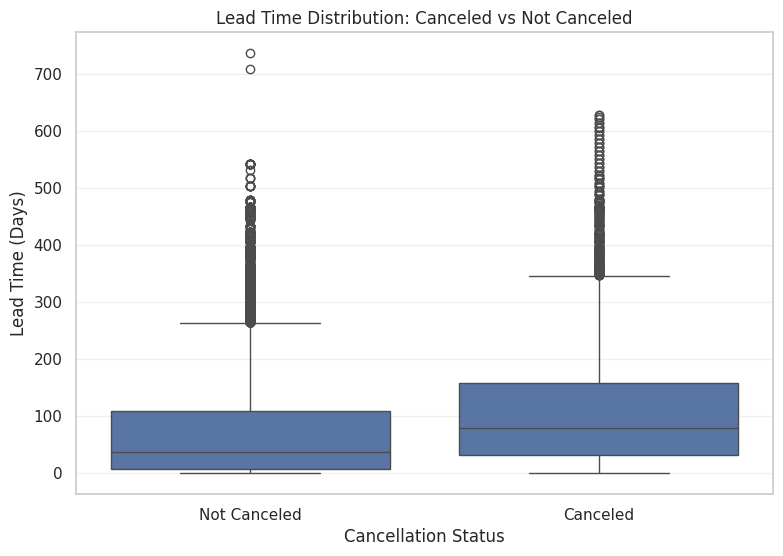

In [43]:
lead_time_summary = (
    df.groupby("cancellation_status")
    .agg(
        total_bookings=("lead_time", "count"),
        average_lead_time=("lead_time", "mean"),
        median_lead_time=("lead_time", "median"),
        minimum_lead_time=("lead_time", "min"),
        maximum_lead_time=("lead_time", "max")
    )
    .reset_index()
)

display(lead_time_summary)

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="cancellation_status",
    y="lead_time"
)

plt.title("Lead Time Distribution: Canceled vs Not Canceled")
plt.xlabel("Cancellation Status")
plt.ylabel("Lead Time (Days)")
plt.grid(axis="y", alpha=0.3)
plt.show()

11. Analyze cancellation rates by lead time groups

,lead_time_group,total_bookings,canceled_bookings,cancellation_rate
0,0-7 Days,18304,1543,8.429851
1,8-30 Days,16340,4145,25.367197
2,31-90 Days,22744,7280,32.008442
3,91-180 Days,18243,6382,34.983281
4,181-365 Days,11199,4444,39.682114
5,Above 365 Days,565,231,40.884956


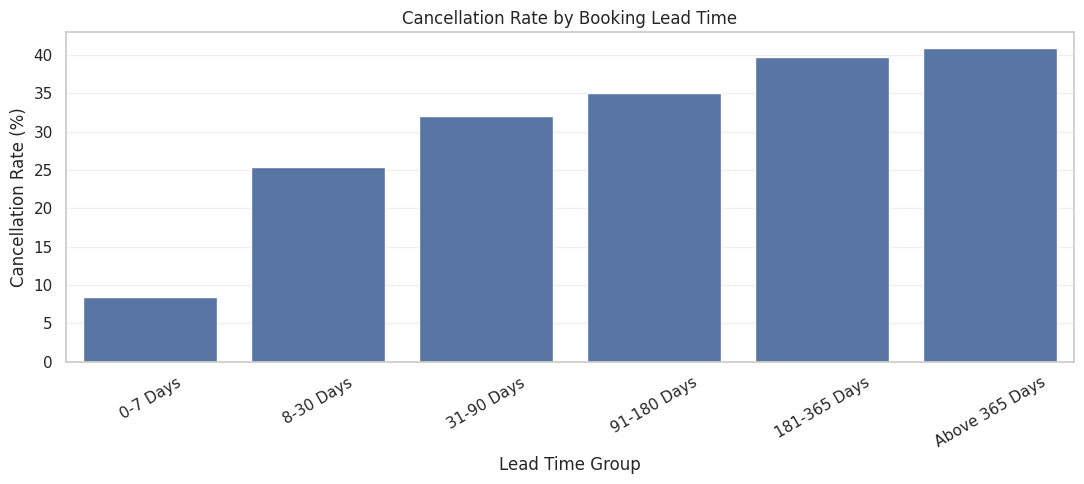

In [44]:
lead_bins = [
    -1, 7, 30, 90, 180, 365, float("inf")
]

lead_labels = [
    "0-7 Days",
    "8-30 Days",
    "31-90 Days",
    "91-180 Days",
    "181-365 Days",
    "Above 365 Days"
]

df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=lead_bins,
    labels=lead_labels
)

lead_group_analysis = (
    df.groupby("lead_time_group", observed=False)
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

lead_group_analysis["cancellation_rate"] = (
    lead_group_analysis["canceled_bookings"] /
    lead_group_analysis["total_bookings"].replace(0, np.nan)
) * 100

display(lead_group_analysis)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=lead_group_analysis,
    x="lead_time_group",
    y="cancellation_rate"
)

plt.title("Cancellation Rate by Booking Lead Time")
plt.xlabel("Lead Time Group")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

12. Compare monthly demand and ADR by hotel type

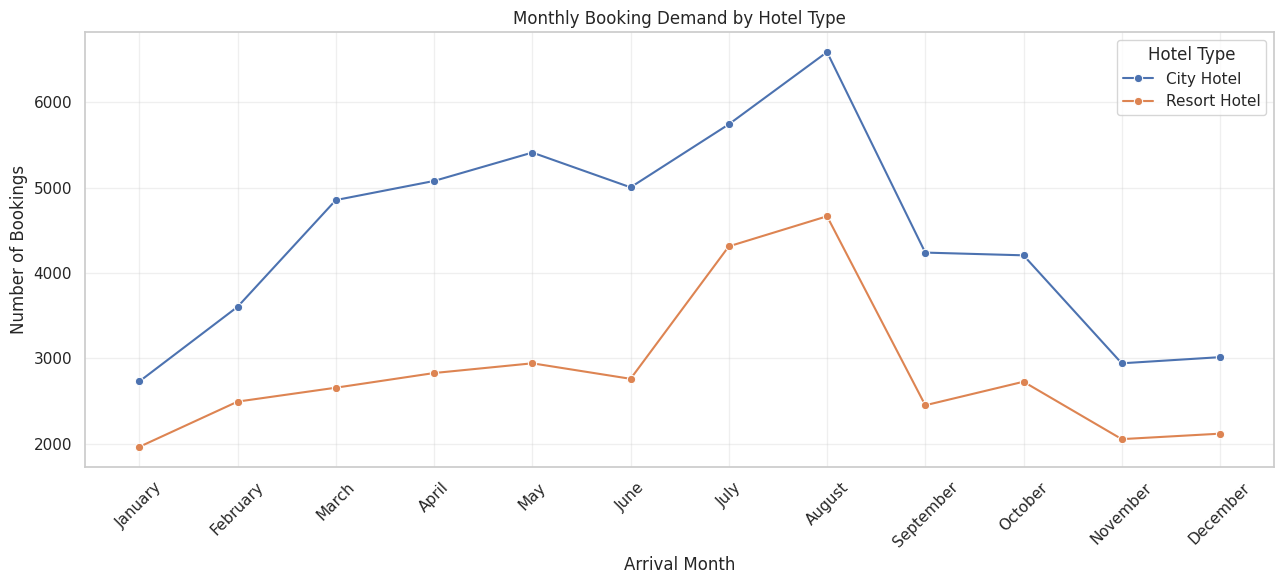

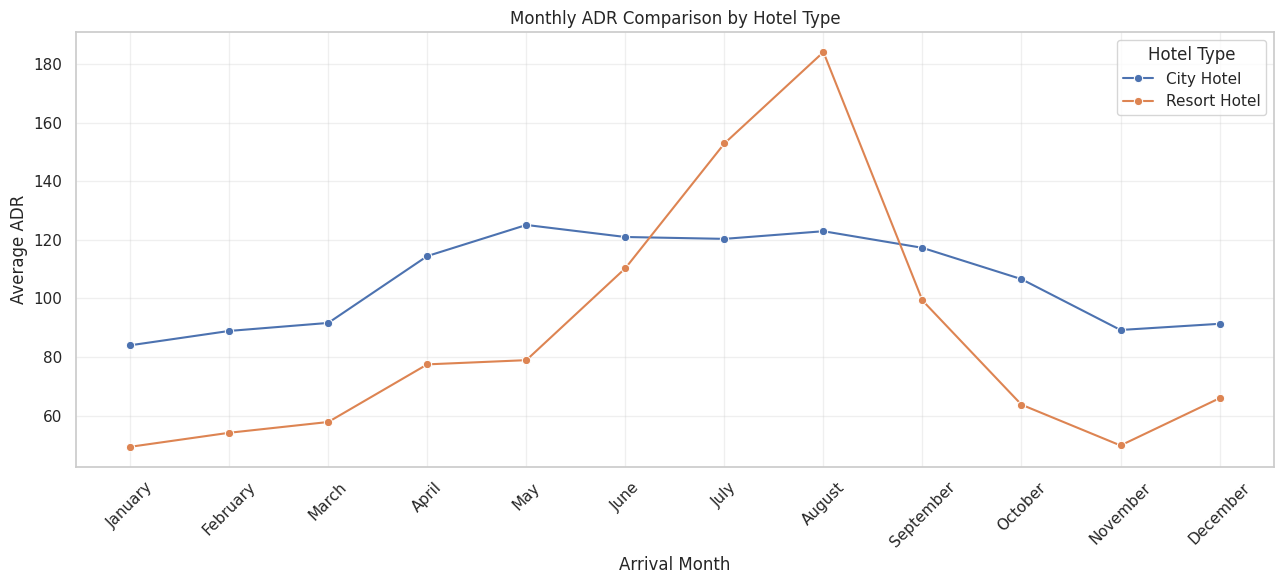

In [45]:
hotel_monthly_demand = (
    df.groupby(["hotel", "arrival_month"])
    .size()
    .reset_index(name="total_bookings")
)

hotel_monthly_adr = (
    completed_stays
    .groupby(["hotel", "arrival_month"])
    .agg(
        average_adr=("adr", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=hotel_monthly_demand,
    x="arrival_month",
    y="total_bookings",
    hue="hotel",
    marker="o"
)

plt.title("Monthly Booking Demand by Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.xticks(range(1, 13), month_order, rotation=45)
plt.legend(title="Hotel Type")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=hotel_monthly_adr,
    x="arrival_month",
    y="average_adr",
    hue="hotel",
    marker="o"
)

plt.title("Monthly ADR Comparison by Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Average ADR")
plt.xticks(range(1, 13), month_order, rotation=45)
plt.legend(title="Hotel Type")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

13. Analyze estimated revenue from completed stays

,hotel,completed_bookings,average_adr,total_nights,estimated_revenue
0,City Hotel,37108,109.075789,111829,12159645.91
1,Resort Hotel,25640,94.242912,109171,10817314.22


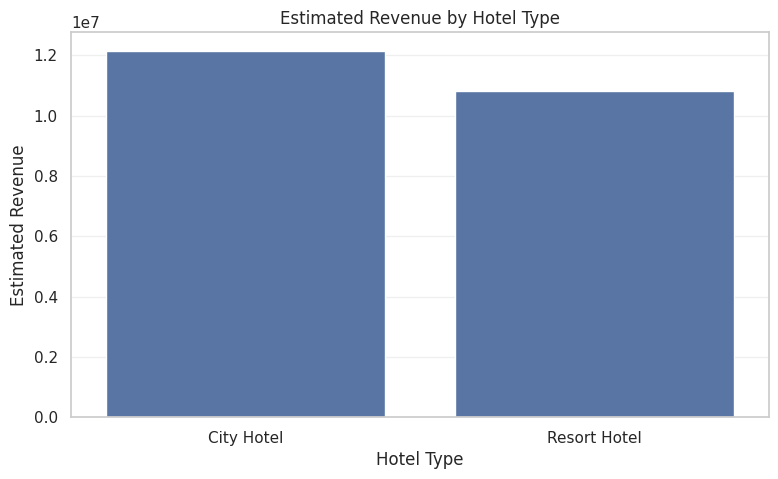

In [46]:
completed_stays["estimated_booking_revenue"] = (
    completed_stays["adr"] *
    completed_stays["total_nights"]
)

hotel_revenue = (
    completed_stays
    .groupby("hotel")
    .agg(
        completed_bookings=("hotel", "count"),
        average_adr=("adr", "mean"),
        total_nights=("total_nights", "sum"),
        estimated_revenue=("estimated_booking_revenue", "sum")
    )
    .reset_index()
)

display(hotel_revenue)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hotel_revenue,
    x="hotel",
    y="estimated_revenue"
)

plt.title("Estimated Revenue by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Estimated Revenue")
plt.grid(axis="y", alpha=0.3)
plt.show()

14. Generate the executive revenue management report

In [47]:
total_bookings = len(df)

total_cancellations = int(df["is_canceled"].sum())

overall_cancellation_rate = (
    total_cancellations / total_bookings
) * 100

highest_demand_hotel = hotel_demand.loc[
    hotel_demand["total_bookings"].idxmax()
]

highest_cancellation_hotel = hotel_cancellation.loc[
    hotel_cancellation["cancellation_rate"].idxmax()
]

highest_cancellation_segment = market_analysis.loc[
    market_analysis["cancellation_rate"].idxmax()
]

highest_risk_lead_group = lead_group_analysis.loc[
    lead_group_analysis["cancellation_rate"].idxmax()
]

peak_arrival_months = monthly_arrivals.loc[
    monthly_arrivals.groupby("arrival_year")[
        "total_arrivals"
    ].idxmax()
]

peak_adr_months = monthly_adr.loc[
    monthly_adr.groupby("arrival_year")[
        "average_adr"
    ].idxmax()
]

total_estimated_revenue = (
    completed_stays["estimated_booking_revenue"].sum()
)

executive_report = []

executive_report.append(
    "EXECUTIVE REVENUE MANAGEMENT REPORT"
)

executive_report.append(
    "HOTEL BOOKING VISUALIZATION AND HOSPITALITY INSIGHTS"
)

executive_report.append("")

executive_report.append("1. OVERALL BOOKING PERFORMANCE")

executive_report.append(
    f"Total bookings analyzed: {total_bookings:,}"
)

executive_report.append(
    f"Total canceled bookings: {total_cancellations:,}"
)

executive_report.append(
    f"Overall cancellation rate: {overall_cancellation_rate:.2f}%"
)

executive_report.append("")

executive_report.append("2. HOTEL-WISE DEMAND ANALYSIS")

executive_report.append(
    f"Hotel with highest booking demand: "
    f"{highest_demand_hotel['hotel']}"
)

executive_report.append(
    f"Total bookings: "
    f"{int(highest_demand_hotel['total_bookings']):,}"
)

executive_report.append(
    f"Hotel with highest cancellation rate: "
    f"{highest_cancellation_hotel['hotel']}"
)

executive_report.append(
    f"Cancellation rate: "
    f"{highest_cancellation_hotel['cancellation_rate']:.2f}%"
)

executive_report.append("")

executive_report.append("3. MARKET SEGMENT ANALYSIS")

executive_report.append(
    f"Market segment with highest cancellation rate: "
    f"{highest_cancellation_segment['market_segment']}"
)

executive_report.append(
    f"Bookings in this segment: "
    f"{int(highest_cancellation_segment['total_bookings']):,}"
)

executive_report.append(
    f"Cancellation rate: "
    f"{highest_cancellation_segment['cancellation_rate']:.2f}%"
)

executive_report.append("")

executive_report.append("4. LEAD TIME AND CANCELLATION RISK")

executive_report.append(
    f"Lead-time group with highest cancellation rate: "
    f"{highest_risk_lead_group['lead_time_group']}"
)

executive_report.append(
    f"Bookings in this group: "
    f"{int(highest_risk_lead_group['total_bookings']):,}"
)

executive_report.append(
    f"Cancellation rate: "
    f"{highest_risk_lead_group['cancellation_rate']:.2f}%"
)

executive_report.append("")

executive_report.append("5. SEASONAL ARRIVAL ANALYSIS")

for _, row in peak_arrival_months.iterrows():

    executive_report.append(
        f"Peak arrival month in {int(row['arrival_year'])}: "
        f"{row['arrival_month_name']} "
        f"with {int(row['total_arrivals']):,} bookings"
    )

executive_report.append("")

executive_report.append("6. ADR ANALYSIS")

for _, row in peak_adr_months.iterrows():

    executive_report.append(
        f"Highest ADR month in {int(row['arrival_year'])}: "
        f"{row['arrival_month_name']} "
        f"with average ADR of {row['average_adr']:.2f}"
    )

executive_report.append("")

executive_report.append("7. ESTIMATED REVENUE")

executive_report.append(
    f"Estimated revenue from completed stays: "
    f"{total_estimated_revenue:,.2f}"
)

executive_report.append("")

executive_report.append("8. REVENUE MANAGEMENT RECOMMENDATIONS")

executive_report.append(
    "Pricing Optimization: Review monthly arrival demand and ADR "
    "together. Consider higher rates during consistently high-demand "
    "periods and suitable promotions during lower-demand periods."
)

executive_report.append(
    "Hotel-Specific Pricing: Develop separate pricing strategies "
    "for City Hotel and Resort Hotel because their demand and "
    "cancellation patterns may differ."
)

executive_report.append(
    "Cancellation Prevention: Review the market segments with "
    "higher cancellation rates. Consider suitable deposit policies, "
    "clear cancellation terms, and booking confirmation reminders."
)

executive_report.append(
    "Lead-Time Monitoring: Monitor bookings made far in advance "
    "when their observed cancellation rate is high. Use reminders "
    "and appropriate confirmation procedures."
)

executive_report.append(
    "Seasonal Planning: Use monthly arrival trends to plan staffing, "
    "room preparation, supplies, and promotional campaigns."
)

executive_report.append(
    "Overbooking Protection: Do not overbook using the overall "
    "cancellation rate alone. Consider hotel type, arrival date, "
    "market segment, lead time, room availability, and expected "
    "no-shows. Apply any overbooking limit only after checking "
    "historical patterns and current room inventory."
)

executive_report.append("")

executive_report.append("9. ANALYSIS LIMITATIONS")

executive_report.append(
    "Estimated revenue is calculated as ADR multiplied by total nights "
    "for completed stays. It is not actual accounting revenue."
)

executive_report.append(
    "The dataset does not provide total available room inventory, "
    "so occupancy rate and RevPAR cannot be calculated reliably."
)

executive_report.append(
    "The analysis identifies historical relationships and does not "
    "guarantee future demand or cancellation behavior."
)

executive_report_text = "\n".join(executive_report)

print(executive_report_text)

with open(
    "executive_revenue_management_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(executive_report_text)

EXECUTIVE REVENUE MANAGEMENT REPORT
HOTEL BOOKING VISUALIZATION AND HOSPITALITY INSIGHTS

1. OVERALL BOOKING PERFORMANCE
Total bookings analyzed: 87,395
Total canceled bookings: 24,025
Overall cancellation rate: 27.49%

2. HOTEL-WISE DEMAND ANALYSIS
Hotel with highest booking demand: City Hotel
Total bookings: 53,428
Hotel with highest cancellation rate: City Hotel
Cancellation rate: 30.04%

3. MARKET SEGMENT ANALYSIS
Market segment with highest cancellation rate: Undefined
Bookings in this segment: 2
Cancellation rate: 100.00%

4. LEAD TIME AND CANCELLATION RISK
Lead-time group with highest cancellation rate: Above 365 Days
Bookings in this group: 565
Cancellation rate: 40.88%

5. SEASONAL ARRIVAL ANALYSIS
Peak arrival month in 2015: September with 2,839 bookings
Peak arrival month in 2016: August with 4,423 bookings
Peak arrival month in 2017: May with 4,575 bookings

6. ADR ANALYSIS
Highest ADR month in 2015: August with average ADR of 122.62
Highest ADR month in 2016: August with a

15. Export all analysis reports

In [48]:
os.makedirs("week14_reports", exist_ok=True)

hotel_demand.to_csv(
    "week14_reports/hotel_demand_summary.csv",
    index=False
)

hotel_cancellation.to_csv(
    "week14_reports/hotel_cancellation_summary.csv",
    index=False
)

market_analysis.to_csv(
    "week14_reports/market_segment_cancellation.csv",
    index=False
)

segment_hotel_analysis.to_csv(
    "week14_reports/segment_hotel_cancellation.csv",
    index=False
)

monthly_arrivals.to_csv(
    "week14_reports/monthly_arrival_summary.csv",
    index=False
)

monthly_adr.to_csv(
    "week14_reports/monthly_adr_summary.csv",
    index=False
)

lead_time_summary.to_csv(
    "week14_reports/lead_time_summary.csv",
    index=False
)

lead_group_analysis.to_csv(
    "week14_reports/lead_time_cancellation_summary.csv",
    index=False
)

hotel_monthly_demand.to_csv(
    "week14_reports/hotel_monthly_demand.csv",
    index=False
)

hotel_monthly_adr.to_csv(
    "week14_reports/hotel_monthly_adr.csv",
    index=False
)

hotel_revenue.to_csv(
    "week14_reports/hotel_revenue_summary.csv",
    index=False
)

with open(
    "week14_reports/executive_revenue_management_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(executive_report_text)

print("All Week 14 reports exported successfully.")

print("\nGenerated Files:")
for file_name in sorted(os.listdir("week14_reports")):
    print(file_name)

All Week 14 reports exported successfully.

Generated Files:
executive_revenue_management_report.txt
hotel_cancellation_summary.csv
hotel_demand_summary.csv
hotel_monthly_adr.csv
hotel_monthly_demand.csv
hotel_revenue_summary.csv
lead_time_cancellation_summary.csv
lead_time_summary.csv
market_segment_cancellation.csv
monthly_adr_summary.csv
monthly_arrival_summary.csv
segment_hotel_cancellation.csv
